# Get to know Infectomics Imaging

How does a cell reorganize itself while a virus takes it over? **Infectomics Imaging**
([s3://bh-infectomics](https://registry.opendata.aws/infectomics-imaging/)) is the live-cell
atlas built to answer that. It is one of three parts of the infectomics resource: the
**Organelle Box** cell lines, this **imaging** release, and **DynaCell**, the deep learning
framework that profiles and aligns the dynamic cellular responses.

The release holds 62 imaging acquisitions of live A549 cells, each carrying one GFP-tagged
organelle or cell-state marker, imaged through Dengue, Zika and herpes simplex virus
infection and through four drug treatments. Two microscopes contribute: the **Mantis**
correlative label-free and light-sheet microscope, which follows single cells every
30 minutes, and an **Andor Dragonfly** spinning-disk confocal, which screens the whole
cell-line panel every 6 hours. Every field of view pairs a label-free 3D phase volume with
the fluorescence channels.

Nothing here is downloaded in full. Every image in this notebook is streamed from S3 with
HTTP range requests, a few megabytes at a time. The notebook has three parts:

1. **What is in the bucket** — the stores, and the curation table each one carries.
2. **The single-cell atlas** — the embedding behind the interactive explorer.
3. **What the images look like** — organelles across infections, and one infection in time.

More tutorials and datasets at the [Registry of Open Data on AWS](https://registry.opendata.aws/).

In [1]:
# Requires: boto3>=1.34, fsspec[http]>=2024, zarr>=3, pyarrow>=14, numpy>=1.26, matplotlib>=3.8
# Install with pip, conda or uv, as suits your environment.

import io
import json
import time
from concurrent.futures import ThreadPoolExecutor

import boto3
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import zarr
from botocore import UNSIGNED
from botocore.config import Config

BUCKET = "bh-infectomics"
PREFIX = "v1/"
HTTPS_BASE = f"https://{BUCKET}.s3.amazonaws.com/{PREFIX}"

# The bucket is public, so list it without credentials.
s3 = boto3.client("s3", region_name="us-east-1", config=Config(signature_version=UNSIGNED))

# trust_env lets the HTTP client use a proxy from the environment; it is harmless without one.
fs = fsspec.filesystem("http", client_kwargs={"trust_env": True})


def retry(call, attempts=4):
    """Run call(), repeating it when a streamed read trips over a transient network error."""
    for attempt in range(attempts):
        try:
            return call()
        except Exception:
            if attempt == attempts - 1:
                raise
            time.sleep(1.5 * (attempt + 1))


def open_store(store):
    """Open one OME-Zarr store over HTTPS. Returns (mapper, group).

    The mapper reads JSON metadata keys such as mapper["zarr.json"]. The group gives array
    access, where each slice pulls only the chunks it touches.
    """
    mapper = fs.get_mapper(HTTPS_BASE + store)
    return mapper, zarr.open_group(mapper, mode="r", zarr_format=3)


def read_bytes(key):
    """Read one object from the bucket into memory."""
    return s3.get_object(Bucket=BUCKET, Key=key)["Body"].read()


def obs_table(store):
    """The per-field-of-view curation table of a store, as a pyarrow Table."""
    return pq.read_table(io.BytesIO(read_bytes(f"{PREFIX}{store}/tables/obs/obs.parquet")))


plt.rcParams.update({"figure.facecolor": "black", "savefig.facecolor": "black"})

## 1. What is in the bucket

Everything sits under the `v1/` prefix, one OME-Zarr store per acquisition. Each acquisition
has a second store with the suffix `_mip`: the same data as maximum-intensity projections
along z, about seventy times smaller, which is what this notebook reads.

In [2]:
def list_stores():
    """Names of the OME-Zarr stores under v1/."""
    stores, token = [], None
    while True:
        page = s3.list_objects_v2(
            Bucket=BUCKET,
            Prefix=PREFIX,
            Delimiter="/",
            **({"ContinuationToken": token} if token else {}),
        )
        stores += [p["Prefix"][len(PREFIX) : -1] for p in page.get("CommonPrefixes", [])]
        token = page.get("NextContinuationToken")
        if not token:
            break
    return stores


stores = list_stores()
mips = [s for s in stores if s.endswith(("_mip.zarr", "_mip.ome.zarr"))]
acquisitions = [s for s in stores if s not in set(mips)]

print(f"{len(acquisitions)} acquisitions, each with a _mip companion ({len(mips)} of them)\n")
print("The last five acquisition names, alphabetically:")
for name in sorted(acquisitions)[-5:]:
    print("  ", name)

62 acquisitions, each with a _mip companion (62 of them)

The last five acquisition names, alphabetically:
   2026_09_22_A549_PCNA_DENV_ZIKV.ome.zarr
   2026_09_25_A549_PCNA_DENV_ZIKV.ome.zarr
   mantis_figure_4.zarr
   mantis_figure_5.zarr
   organelle_box_v2.ome.zarr


### The curation table every store carries

A store is not only pixels. Each one holds `tables/obs/obs.parquet`, one row per field of
view, with the marker, the condition, the perturbation and its ontology identifier, the
microscope and its time increment, the voxel size, and the cell line with its Cellosaurus
identifier. The same record, unflattened, sits in the `dca` column as JSON. Reading those
62 tables takes a few seconds and gives the whole release at a glance.

In [3]:
def summarize(store):
    """Release-level summary of one store, read from its curation table.

    Counts of microscopes and perturbations are per field of view, taken from that field's
    own record, so they add up to the number of fields of view. A field given a drug and a
    virus together carries the drug as its perturbation and the virus as its co-treatment;
    both are counted, so co-treated fields appear in two perturbation rows.
    """
    table = retry(lambda: obs_table(store))
    column = dict(zip(table.schema.names, table.columns))
    records = [json.loads(x) for x in column["dca"].to_pylist()]
    cotreatments = column["dca_cotreat_name"].to_pylist() if "dca_cotreat_name" in column else [""] * table.num_rows

    def field(path):
        """Distinct values of a dotted path across the store's records."""
        seen = []
        for record in records:
            value = record
            for part in path.split("."):
                value = value.get(part) if isinstance(value, dict) else None
                if value is None:
                    break
            if value is not None and value not in seen:
                seen.append(value)
        return seen

    scopes, perturbations = {}, {}
    for record, cotreatment in zip(records, cotreatments):
        scope = record["acquisition"]["microscope"]
        scopes[f"{scope['manufacturer']} {scope['model']}"] = (
            scopes.get(f"{scope['manufacturer']} {scope['model']}", 0) + 1
        )
        named = (record.get("perturbation") or {}).get("definition", {}).get("name")
        for label in [named or "(no perturbation recorded)"] + ([cotreatment] if cotreatment else []):
            perturbations[label] = perturbations.get(label, 0) + 1

    markers = sorted(
        {
            channel["biological_annotation"]["marker"]
            for record in records
            for channel in record.get("channels", [])
            if channel.get("biological_annotation", {}).get("marker")
        }
    )
    return {
        "store": store,
        "fovs": table.num_rows,
        "date": sorted(field("acquisition.acquisition_date"))[0][:10] if field("acquisition.acquisition_date") else "",
        "microscopes": scopes,
        "perturbations": perturbations,
        "interval_min": "; ".join(f"{s / 60:g}" for s in field("acquisition.time_increment_s")),
        "markers": markers,
        "license": "; ".join(field("study.license")),
    }


with ThreadPoolExecutor(8) as pool:
    inventory = list(pool.map(summarize, acquisitions))

total_fovs = sum(row["fovs"] for row in inventory)
print(f"{total_fovs:,} fields of view across {len(inventory)} acquisitions")
print(
    f"imaged between {min(r['date'] for r in inventory if r['date'])}"
    f" and {max(r['date'] for r in inventory if r['date'])}\n"
)


def pooled(key):
    counts = {}
    for row in inventory:
        for value, n in row[key].items():
            counts[value] = counts.get(value, 0) + n
    return dict(sorted(counts.items(), key=lambda kv: -kv[1]))


scopes = pooled("microscopes")
print(f"Microscope (fields of view; sums to {sum(scopes.values()):,})")
for value, n in scopes.items():
    print(f"  {value:<62} {n:>6,}")

perturbations = pooled("perturbations")
print(
    f"\nPerturbation (fields of view; sums to {sum(perturbations.values()):,}, above"
    f" {total_fovs:,} because {sum(perturbations.values()) - total_fovs} fields carry"
    " a drug and a virus together)"
)
for value, n in perturbations.items():
    print(f"  {value:<62} {n:>6,}")

markers = sorted({m for row in inventory for m in row["markers"]})
print(f"\n{len(markers)} labelled targets, counting organelle markers, infection sensors, dyes and stains:")
print("  " + ", ".join(markers))

licenses = {}
for row in inventory:
    licenses[row["license"]] = licenses.get(row["license"], 0) + 1
print("\nLicense (acquisitions)")
for value, n in licenses.items():
    print(f"  {value:<56} {n}")

7,845 fields of view across 62 acquisitions
imaged between 2023-09-21 and 2026-09-25

Microscope (fields of view; sums to 7,845)
  Andor Technology Dragonfly                                      6,368
  Chan Zuckerberg Biohub San Francisco Mantis v2                  1,005
  Chan Zuckerberg Biohub San Francisco Mantis v1                    408
  Andor / Oxford Instruments dragonfly                               64

Perturbation (fields of view; sums to 8,320, above 7,845 because 475 fields carry a drug and a virus together)
  no infection                                                    2,316
  Zika virus infection                                            1,642
  Dengue virus infection                                          1,577
  Herpes simplex virus 1 infection                                  896
  (no perturbation recorded)                                        880
  dimethyl sulfoxide (vehicle)                                      523
  MK-0608                              

### One field of view, fully described

The `dca` record is the provenance of a field of view: what was imaged, on what, under what
perturbation, and where each annotated value came from. Printed below for one well of the
6-hourly confocal screen.

In [4]:
SCREEN = "2026_03_31_A549_medium_organelles_DENV_ZIKV_time_course.ome.zarr"

record = json.loads(obs_table(SCREEN).column("dca")[0].as_py())

print("Cell line  :", record["biosample"]["cell_line_name"], f"({record['biosample']['cell_line_id']})")
print("Disease    :", record["biosample"]["disease"][0]["label"])
print("Specimen   :", record["specimen"]["specimen_state"], "-", record["specimen"]["preparation_method"][0]["label"])
print(
    "Microscope :", record["acquisition"]["microscope"]["model"], "-", record["acquisition"]["microscope"]["modality"]
)
print("Interval   :", record["acquisition"]["time_increment_s"] / 3600, "h")
print(
    "Perturbation:",
    record["perturbation"]["definition"]["name"],
    f"({record['perturbation']['definition']['perturbation_id']})",
)
print("\nChannels")
for channel in record["channels"]:
    target = channel.get("biological_annotation", {})
    print(
        f"  {channel['index']}  {channel['name']:<20} {channel['channel_type']:<12}"
        f" {target.get('marker') or target.get('biological_target') or ''}"
    )
print("\nStudy:", record["study"]["dataset_name"])
print("License:", record["study"]["license"])

Cell line  : A549 (CVCL:0023)
Disease    : lung adenocarcinoma
Specimen   : live - adherent live cells
Microscope : Dragonfly - spinning-disk confocal fluorescence and brightfield
Interval   : 6.0 h
Perturbation: Dengue virus infection (NCBITaxon:12637)

Channels
  0  Phase3D              labelfree    
  1  GFP                  fluorescence CLTA
  2  nuclei_prediction    predicted    nucleus
  3  membrane_prediction  predicted    cell membrane

Study: Organelle box -- A549 GFP organelle reporters under DENV / ZIKV infection (2026-03-31)
License: https://creativecommons.org/licenses/by/4.0/


## 2. The single-cell atlas

The images above are the raw material. DynaCell turns each cell, at each timepoint, into an
embedding, and a joint UMAP of those embeddings is the point cloud behind the
[interactive Infectomics Atlas](https://biohub.ai/infectomics/imaging): **251,137 cells**,
**22 organelle markers**, **3 viruses**. Cells of one marker fall together; infection moves
them within their island.

That table is published as `v1/metadata/cells.parquet`. The cell below draws it when the
key is present, and says so plainly when it is not — the imaging release above does not
depend on it.

In [5]:
CELLS_KEY = f"{PREFIX}metadata/cells.parquet"


def load_cells():
    """The atlas table, or None when it is not yet published."""
    try:
        return pq.read_table(io.BytesIO(read_bytes(CELLS_KEY)))
    except s3.exceptions.NoSuchKey:
        return None
    except Exception as error:  # any other access problem
        print(f"Could not read s3://{BUCKET}/{CELLS_KEY}: {error}")
        return None


cells = load_cells()

if cells is None:
    print(f"s3://{BUCKET}/{CELLS_KEY} is not published yet.")
    print("Explore the same embedding interactively at https://biohub.ai/infectomics/imaging")
else:
    table = cells.to_pydict()
    x = np.asarray(table["umap_x"])
    y = np.asarray(table["umap_y"])
    marker = np.asarray(table["marker"])
    names = sorted(set(marker.tolist()))
    colors = plt.get_cmap("tab20")(np.linspace(0, 1, len(names)))

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_facecolor("black")
    for color, name in zip(colors, names):
        hit = marker == name
        ax.scatter(x[hit], y[hit], s=0.6, color=color, linewidths=0, alpha=0.7, label=name)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{len(marker):,} cells, {len(names)} organelle markers", color="white")
    ax.legend(
        loc="center left", bbox_to_anchor=(1.0, 0.5), markerscale=18, frameon=False, labelcolor="white", fontsize=8
    )
    fig.tight_layout()

s3://bh-infectomics/v1/metadata/cells.parquet is not published yet.
Explore the same embedding interactively at https://biohub.ai/infectomics/imaging


## 3. What the images look like

### Organelles across infections

The 6-hourly confocal screen is a plate: one row per organelle marker, one column per
condition. The grid below is the GFP channel at the last timepoint of the time course, one
field of view per well. Fields are chosen by contrast, because a well sometimes holds an
empty or out-of-focus field; wells whose best field stays flat are dropped and named.

No usable field in every condition, dropped: PEX3


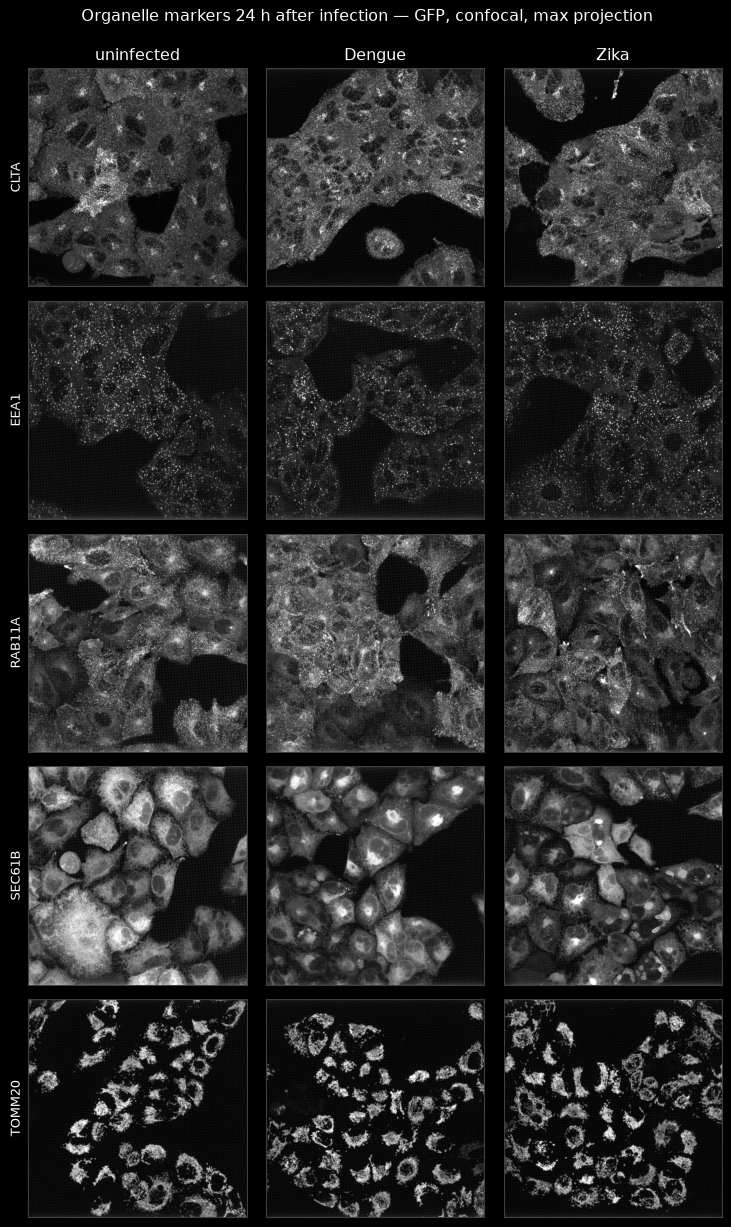

In [6]:
SCREEN_MIP = SCREEN.replace(".ome.zarr", "_mip.ome.zarr")
mapper, screen = open_store(SCREEN_MIP)

plate = json.loads(mapper["zarr.json"])["attributes"]["ome"]["plate"]
marker_rows = [row["name"] for row in plate["rows"]]
conditions = ["uninfected1", "DENV", "ZIKV"]
n_fovs = len(json.loads(mapper[f"{marker_rows[0]}/{conditions[0]}/zarr.json"])["attributes"]["ome"]["well"]["images"])

GFP = 1  # channel order in the _mip stores is (Phase3D, GFP)
CONTRAST_FLOOR = 5.0  # a flat field has almost no spread between its percentiles


def field_contrast(args):
    """Spread of the GFP channel of one field, read at a coarse resolution level."""
    well, index = args
    image = retry(lambda: np.asarray(screen[f"{well}/{index}/2"][-1, GFP, 0]))
    return well, index, float(np.std(image))


wells = [f"{m}/{c}" for m in marker_rows for c in conditions]
with ThreadPoolExecutor(8) as pool:
    scores = list(pool.map(field_contrast, [(w, i) for w in wells for i in range(n_fovs)]))

best = {}
for well, index, spread in scores:
    if well not in best or spread > best[well][1]:
        best[well] = (index, spread)

shown = [m for m in marker_rows if all(best[f"{m}/{c}"][1] >= CONTRAST_FLOOR for c in conditions)]
dropped = [m for m in marker_rows if m not in shown]
if dropped:
    print("No usable field in every condition, dropped:", ", ".join(dropped))

label = {"uninfected1": "uninfected", "DENV": "Dengue", "ZIKV": "Zika"}
fig, axes = plt.subplots(len(shown), len(conditions), figsize=(2.6 * len(conditions), 2.6 * len(shown)))
for i, marker_name in enumerate(shown):
    for j, condition in enumerate(conditions):
        index, _ = best[f"{marker_name}/{condition}"]
        image = retry(lambda: np.asarray(screen[f"{marker_name}/{condition}/{index}/1"][-1, GFP, 0]))
        low, high = np.percentile(image, [1, 99.8])
        ax = axes[i, j]
        ax.imshow(np.clip((image - low) / (high - low + 1e-9), 0, 1) ** 0.7, cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color("0.25")
        if i == 0:
            ax.set_title(label[condition], color="white")
        if j == 0:
            ax.set_ylabel(marker_name, color="white")
fig.suptitle("Organelle markers 24 h after infection — GFP, confocal, max projection", color="white")
fig.tight_layout(rect=[0, 0, 1, 0.985])

### One infection, in time

The confocal screen trades time for breadth. The Mantis acquisitions trade breadth for time:
one marker, one virus, a frame every 30 minutes. The acquisition below follows Dengue
infection of the SEC61B (ER) line at a multiplicity of infection of 5, from 3 hours after
inoculation. Three channels are shown: the label-free phase volume, the ER marker, and an
mCherry protease sensor that moves into the nucleus once the viral protease is active.

Phase reconstruction fails on some frames of some fields, so the cell picks a field whose
phase channel is present at every timepoint it draws.

field of view A/3/001002, 67 frames every 30 min


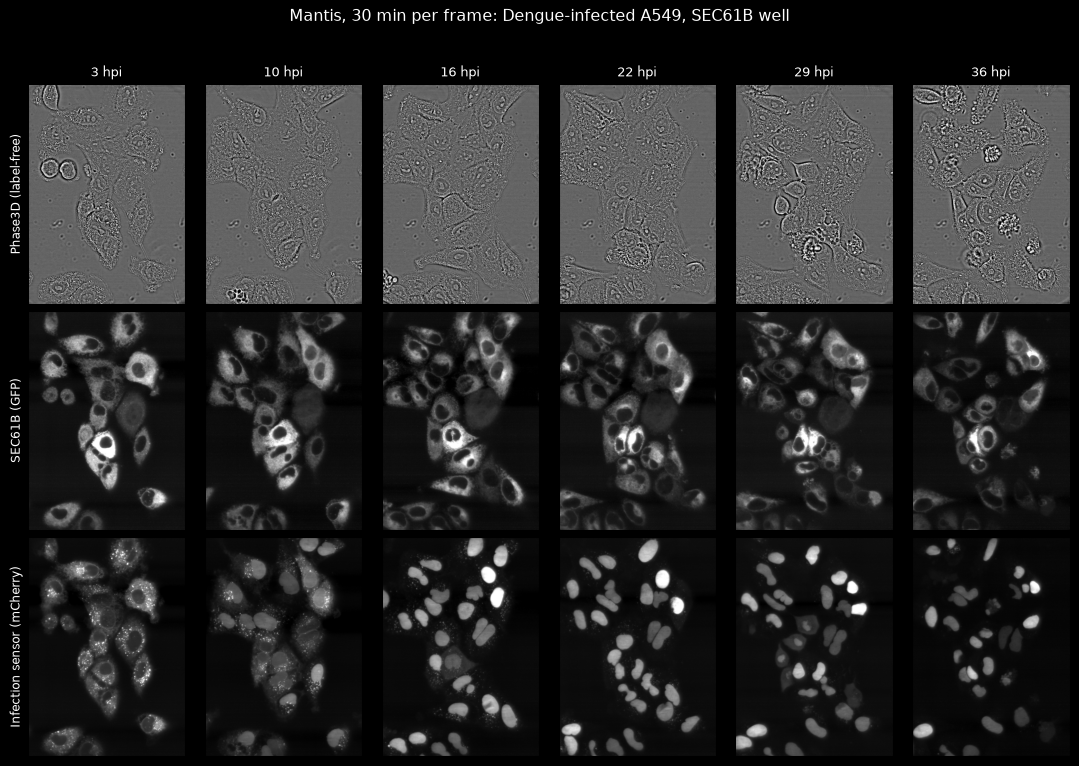

In [7]:
MANTIS = "2026_04_28_A549_SEC61B_DENV_mip.zarr"
WELL = "A/3"  # a Dengue-infected well; A/2 is the mock control
FIRST_HPI = 3  # imaging starts 3 hours after inoculation
INTERVAL_H = 0.5

mantis_mapper, mantis = open_store(MANTIS)
fovs = [
    image["path"] for image in json.loads(mantis_mapper[f"{WELL}/zarr.json"])["attributes"]["ome"]["well"]["images"]
]

channels = [
    c["label"]
    for c in json.loads(mantis_mapper[f"{WELL}/{fovs[0]}/zarr.json"])["attributes"]["ome"]["omero"]["channels"]
]
PHASE = channels.index("Phase3D")
MARKER = channels.index("raw GFP EX488 EM525-45")
SENSOR = channels.index("raw mCherry EX561 EM600-37")

n_times = mantis[f"{WELL}/{fovs[0]}/1"].shape[0]
times = np.linspace(0, n_times - 1, 6).astype(int)


def phase_complete(fov):
    """True when the phase channel holds data at every timepoint drawn."""
    coarse = mantis[f"{WELL}/{fov}/2"]
    return all(retry(lambda: np.ptp(np.asarray(coarse[t, PHASE, 0]))) > 0 for t in times)


fov = next(f for f in fovs if phase_complete(f))
print(f"field of view {WELL}/{fov}, {n_times} frames every {INTERVAL_H * 60:g} min")

volume = retry(lambda: np.asarray(mantis[f"{WELL}/{fov}/1"][times][:, [PHASE, MARKER, SENSOR], 0]))
names = ["Phase3D (label-free)", "SEC61B (GFP)", "Infection sensor (mCherry)"]
gammas = [1.0, 0.8, 0.8]

fig, axes = plt.subplots(3, len(times), figsize=(1.9 * len(times), 2.7 * 3))
for row, (name, gamma) in enumerate(zip(names, gammas)):
    stack = volume[:, row]
    low, high = np.percentile(stack, [1, 99.7])
    for col, t in enumerate(times):
        ax = axes[row, col]
        ax.imshow(np.clip((stack[col] - low) / (high - low + 1e-9), 0, 1) ** gamma, cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"{FIRST_HPI + t * INTERVAL_H:.0f} hpi", color="white", fontsize=10)
        if col == 0:
            ax.set_ylabel(name, color="white", fontsize=9)
fig.suptitle("Mantis, 30 min per frame: Dengue-infected A549, SEC61B well", color="white")
fig.tight_layout(rect=[0, 0, 1, 0.96])

## Where to go next

- **Pipelines** — [VisCy](https://github.com/Biohub/VisCy) trains, predicts and evaluates
  the DynaCell models.
- **I/O** — [iohub](https://github.com/czbiohub-sf/iohub) reads and writes these OME-Zarr
  stores; [waveorder](https://github.com/Biohub/waveorder) reconstructs the phase volumes.
- **Cell lines** — the [Organelle Box](https://biohub.ai/infectomics/organellebox).
- **Explore** — the [Infectomics Atlas](https://biohub.ai/infectomics/imaging).